# **Ejercicio 2: Proxies de calidad del agua a partir de imágenes satelitales**

## Caso de estudio: Lago Titicaca – Bolivia

---

En este ejercicio utilizaremos imágenes satelitales para explorar algunas
propiedades relacionadas con la calidad superficial del agua en el
**Lago Titicaca**.

Utilizaremos tres sensores complementarios:

- **Sentinel-2 MSI**
- **MODIS Aqua**
- **Sentinel-3**

Analizaremos cuatro variables relacionadas con la calidad del agua:

- clorofila-a;
- turbidez;
- sólidos suspendidos;
- temperatura superficial.

La pregunta que guiará el ejercicio será:

> **¿Qué información sobre la calidad superficial del agua podemos obtener
> desde el espacio y qué información complementaria aportan Sentinel-2
> y MODIS?**

A lo largo del ejercicio diferenciaremos entre:

**proxies espectrales**

y

**productos satelitales derivados**.

# 0. Introducción

La calidad del agua puede variar considerablemente dentro de un lago.

Algunos factores que pueden modificar sus propiedades ópticas son:

- fitoplancton y algas;
- sedimentos suspendidos;
- materia orgánica disuelta;
- vegetación acuática;
- profundidad del agua.

Los satélites ópticos no miden directamente la "calidad del agua".

Los sensores registran la radiación que llega hasta ellos en diferentes
regiones del espectro electromagnético.

De manera simplificada:

**Radiación solar**

**Superficie del agua**

**Absorción + dispersión**

**Señal espectral**

**Sensor satelital**

**Bandas espectrales**

**Índices o algoritmos**

**Información relacionada con calidad del agua**

---

En este ejercicio exploraremos cómo distintas características espectrales
pueden utilizarse como indicadores de condiciones superficiales del agua.

# 1. Objetivos del ejercicio

Al finalizar este ejercicio podrás:

1. Acceder a imágenes Sentinel-2 y MODIS desde Google Earth Engine.

2. Reconocer algunas bandas espectrales relevantes para el monitoreo
   de calidad del agua.

3. Crear un compuesto Sentinel-2 con baja presencia de nubes.

4. Delimitar aproximadamente la superficie de agua mediante MNDWI.

5. Calcular el **Normalized Difference Chlorophyll Index (NDCI)**
   como proxy relativo de clorofila-a.

6. Calcular el **Normalized Difference Turbidity Index (NDTI)**
   como proxy relativo de turbidez.

7. Utilizar la reflectancia en la banda roja como indicador relativo
   de material suspendido.

8. Explorar productos MODIS de:
   - clorofila-a;
   - temperatura superficial.

9. Comparar información obtenida con sensores de diferente
   resolución espacial.

10. Reconocer las principales limitaciones de los productos
    satelitales de calidad del agua.

# 2. ¿Qué podemos observar desde el espacio?

No todas las variables de calidad del agua pueden observarse directamente
mediante sensores satelitales.

En este ejercicio trabajaremos con cuatro variables.

| Variable | Información satelital utilizada |
|---|---|
| Clorofila-a | Sentinel-2 NDCI + MODIS chlor_a |
| Turbidez | Sentinel-2 NDTI |
| Sólidos suspendidos | Reflectancia roja Sentinel-2 |
| Temperatura superficial | MODIS SST |

---

## Dos conceptos importantes

### Proxy espectral

Es una variable calculada a partir de la reflectancia que puede estar
relacionada con una propiedad del agua.

Ejemplos:

- NDCI;
- NDTI;
- reflectancia roja.

Un proxy permite comparar espacialmente condiciones relativas, pero
**no representa automáticamente una concentración física**.

---

### Producto derivado

Es una variable estimada mediante un algoritmo desarrollado y procesado
por una agencia o institución.

Por ejemplo, MODIS proporciona directamente:

- `chlor_a` en mg/m³;
- `sst` en °C.

Sin embargo, incluso estos productos siguen siendo estimaciones
satelitales y presentan incertidumbre.

# 3. Datos satelitales utilizados

## Sentinel-2 MSI

Utilizaremos:

`COPERNICUS/S2_SR_HARMONIZED`

Sentinel-2 proporciona imágenes multiespectrales de alta resolución espacial.

Las principales bandas que utilizaremos son:

| Banda | Región | Resolución | Uso |
|---|---|---:|---|
| B2 | Azul | 10 m | Color natural |
| B3 | Verde | 10 m | Agua / turbidez |
| B4 | Rojo | 10 m | Turbidez / sólidos suspendidos |
| B5 | Red Edge | 20 m | Clorofila |
| B11 | SWIR | 20 m | Máscara de agua |

---

## MODIS Aqua

Utilizaremos:

`NASA/OCEANDATA/MODIS-Aqua/L3SMI`

Este producto contiene variables derivadas relacionadas con color
del océano y temperatura superficial.

Utilizaremos:

| Banda | Variable | Unidad |
|---|---|---|
| chlor_a | Clorofila-a | mg/m³ |
| sst | Temperatura superficial | °C |

La resolución espacial es de aproximadamente **4.6 km**.

---

## Pregunta

Antes de comenzar:

> ¿Qué ventajas y desventajas esperarías encontrar al comparar un sensor
> de 10–20 m con otro de aproximadamente 4.6 km?

# 4. Preparación del entorno

Utilizaremos las siguientes librerías:

- `ee`: Google Earth Engine;
- `geemap`: visualización de mapas;
- `pandas`: tablas;
- `numpy`: operaciones numéricas;
- `matplotlib`: gráficos.

In [52]:
# ============================================================
# Importar librerías
# ============================================================

import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## Autenticación en Google Earth Engine

Utilizaremos el mismo procedimiento del ejercicio anterior.

Al ejecutar la siguiente celda aparecerá un enlace.

1. Abre el enlace.
2. Autoriza tu cuenta.
3. Copia el código generado.
4. Pégalo nuevamente en Colab.

In [53]:
# ---------------------------------------------------------------------------
# Autenticar e inicializar Earth Engine
# ---------------------------------------------------------------------------
# >>> REEMPLAZAR por el id de su propio proyecto de Cloud <<<
EE_PROJECT = "ee-edwinyucra"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

print("Google Earth Engine inicializado correctamente.")

Google Earth Engine inicializado correctamente.


# 5. Área de estudio

Nuestro análisis se concentrará en el sector boliviano del
**Lago Menor o Wiñaymarca**.

Dentro del área se encuentra la **Bahía de Cohana**, localizada en la
ribera oriental del lago y asociada a la desembocadura del río Katari.

La zona constituye un caso interesante porque permite comparar:

- ambientes costeros;
- bahías someras;
- sectores próximos a entradas fluviales;
- aguas más abiertas del lago.

Definiremos una ventana rectangular suficientemente grande para
incluir Cohana y sectores abiertos del Lago Menor.

In [54]:
# ============================================================
# Área de estudio: Lago Titicaca completo + buffer
# Sin polígonos interiores
# ============================================================

# Cargar HydroLAKES
hydrolakes = ee.FeatureCollection(
    "projects/sat-io/open-datasets/HydroLakes/lake_poly_v10"
)

# Región de búsqueda
search_area = ee.Geometry.Rectangle([
    -70.20,  # oeste
    -16.80,  # sur
    -68.40,  # este
    -15.10   # norte
])

# Seleccionar el lago de mayor superficie
lake = ee.Feature(
    hydrolakes
    .filterBounds(search_area)
    .sort("Lake_area", False)
    .first()
)

# ============================================================
# Aplicar buffer
# ============================================================

lake_geometry = lake.geometry()

# Distancia del buffer (metros)
BUFFER_M = 3000

roi_buffer = lake_geometry.buffer(BUFFER_M)

# ============================================================
# Eliminar anillos interiores
# ============================================================

geometry_type = roi_buffer.type().getInfo()

print("Tipo de geometría:", geometry_type)

if geometry_type == "Polygon":

    # Conservar únicamente el anillo exterior
    outer_ring = ee.List(
        roi_buffer.coordinates()
    ).get(0)

    roi = ee.Geometry.Polygon(outer_ring)

elif geometry_type == "MultiPolygon":

    # Extraer el anillo exterior de cada polígono
    parts = ee.List(roi_buffer.coordinates())

    def remove_holes(part):

        outer_ring = ee.List(part).get(0)

        polygon = ee.Geometry.Polygon(outer_ring)

        return ee.Feature(polygon).set(
            "area_m2",
            polygon.area(maxError=10)
        )

    polygons = ee.FeatureCollection(
        parts.map(remove_holes)
    )

    # Conservar el polígono exterior más grande
    roi = ee.Feature(
        polygons
        .sort("area_m2", False)
        .first()
    ).geometry()

else:
    raise ValueError(
        f"Tipo de geometría no esperado: {geometry_type}"
    )

# ============================================================
# Información del área de estudio
# ============================================================

print("Lago:", lake.get("Lake_name").getInfo())

print(
    "Área original del lago:",
    lake.get("Lake_area").getInfo(),
    "km²"
)

print(
    "Buffer:",
    BUFFER_M / 1000,
    "km"
)

print(
    "Área final del ROI:",
    round(
        roi.area(maxError=10).divide(1e6).getInfo(),
        1
    ),
    "km²"
)

print("Área de estudio definida sin huecos interiores.")

Tipo de geometría: Polygon
Lago: Titicaca
Área original del lago: 8002.51 km²
Buffer: 3.0 km
Área final del ROI: 10716.6 km²
Área de estudio definida sin huecos interiores.


In [55]:
# ============================================================
# Visualizar ROI - Lago Titicaca + buffer de 3 km
# ============================================================

Map_roi = geemap.Map()

Map_roi.centerObject(roi, 9)

Map_roi.add_basemap("HYBRID")

# Visualizar únicamente el límite del ROI
Map_roi.addLayer(
    ee.FeatureCollection([
        ee.Feature(roi)
    ]).style(
        color="red",
        fillColor="00000000",
        width=2
    ),
    {},
    "Área de estudio (ROI)"
)

Map_roi

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Observa el área

Identifica:

- sectores costeros;
- islas;
- zonas abiertas del Lago Menor.

### Pregunta

> ¿Esperaríamos encontrar las mismas condiciones de calidad del agua
> dentro de una bahía costera que en aguas más abiertas?

# 6. Exploración de Sentinel-2

Trabajaremos con el período:

**1 de julio – 31 de agosto de 2025**

Esta ventana corresponde a la estación seca del Altiplano y permite
trabajar con un período relativamente corto y reciente.

En lugar de seleccionar una única imagen construiremos un
**compuesto mediano**.

Esto ayuda a reducir:

- nubes residuales;
- valores extremos;
- pequeñas diferencias entre fechas.

El procedimiento será:

Sentinel-2

↓

filtrar área

↓

filtrar período

↓

filtrar escenas muy nubladas

↓

enmascarar nubes

↓

calcular mediana

In [56]:
# ============================================================
# Definir período
# ============================================================

START_DATE = "2025-05-01"
END_DATE   = "2025-07-01"

print(
    "Período:",
    START_DATE,
    "a",
    END_DATE
)

Período: 2025-05-01 a 2025-07-01


In [57]:
# ============================================================
# Cargar Sentinel-2
# ============================================================

s2 = (
    ee.ImageCollection(
        "COPERNICUS/S2_SR_HARMONIZED"
    )
    .filterBounds(roi)
    .filterDate(
        START_DATE,
        END_DATE
    )
    .filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE",
            20
        )
    )
)

print(
    "Número de imágenes:",
    s2.size().getInfo()
)

Número de imágenes: 85


## Máscara sencilla de nubes

Sentinel-2 incluye una banda denominada `SCL`
(Scene Classification Layer).

Esta banda clasifica diferentes tipos de píxeles.

Para mantener el ejercicio sencillo eliminaremos solamente:

- píxeles saturados;
- sombras de nubes;
- nubes;
- cirrus;
- nieve/hielo.

Esta es una máscara simplificada apropiada para el ejercicio.

En aplicaciones operativas pueden utilizarse procedimientos de
enmascaramiento atmosférico más avanzados.

In [58]:
# ============================================================
# Función para eliminar nubes
# ============================================================

def mask_clouds(image):

    scl = image.select("SCL")

    clear = (
        scl.neq(1)   # saturado
        .And(scl.neq(3))   # sombra
        .And(scl.neq(8))   # nube media
        .And(scl.neq(9))   # nube alta
        .And(scl.neq(10))  # cirrus
        .And(scl.neq(11))  # nieve/hielo
    )

    return image.updateMask(clear)

In [59]:
# ============================================================
# Crear compuesto Sentinel-2
# ============================================================

s2_composite = (
    s2
    .map(mask_clouds)
    .median()
    .select([
        "B2",
        "B3",
        "B4",
        "B5",
        "B8",
        "B11"
    ])
    .multiply(0.0001)
    .clip(roi)
)

print(
    "Compuesto Sentinel-2 preparado."
)

Compuesto Sentinel-2 preparado.


In [60]:
# ============================================================
# Visualización en color natural
# ============================================================

rgb_vis = {
    "bands": ["B4", "B3", "B2"],
    "min": 0.0,
    "max": 0.25,
    "gamma": 1.2
}

Map_rgb = geemap.Map()

Map_rgb.centerObject(
    roi,
    9
)

# Agregar mapa base ESRI World Imagery
Map_rgb.add_basemap(
    "HYBRID"
)

Map_rgb.addLayer(
    s2_composite,
    rgb_vis,
    "Sentinel-2 RGB"
)

Map_rgb

Map(center=[-15.900307221437474, -69.3388988040462], controls=(WidgetControl(options=['position', 'transparent…

### Primero observa la imagen

Antes de calcular cualquier índice:

1. observa el color del agua;
2. identifica zonas claras y oscuras;
3. observa los sectores próximos a Cohana;
4. compara la bahía con zonas abiertas.

### Preguntas

> ¿El color del agua es homogéneo en toda el área?

> ¿Puedes reconocer visualmente sectores con agua más verdosa o turbia?

No interpretes todavía estos colores como concentraciones.

Primero calcularemos algunos indicadores espectrales.

# 7. Máscara de agua: MNDWI

Antes de analizar calidad del agua necesitamos distinguir aproximadamente
los píxeles de agua de los píxeles terrestres.

Utilizaremos el:

**Modified Normalized Difference Water Index (MNDWI)**

\[
MNDWI =
\frac{Green-SWIR}
{Green+SWIR}
\]

Para Sentinel-2:

\[
MNDWI =
\frac{B3-B11}
{B3+B11}
\]

En este ejercicio utilizaremos:

**MNDWI > 0**

como una máscara sencilla de agua.

In [61]:
# ============================================================
# Calcular MNDWI
# ============================================================

mndwi = (
    s2_composite
    .normalizedDifference([
        "B3",
        "B11"
    ])
    .rename("MNDWI")
)

water_mask = mndwi.gt(0)

print("MNDWI calculado.")

MNDWI calculado.


In [62]:
# ============================================================
# Visualizar MNDWI
# ============================================================

mndwi_vis = {
    "min": -0.5,
    "max": 0.7,
    "palette": [
        "8c510a",
        "f6e8c3",
        "ffffff",
        "67a9cf",
        "2166ac"
    ]
}

Map_water = geemap.Map()

Map_water.centerObject(
    roi,
    9
)

# Agregar mapa base ESRI World Imagery
Map_water.add_basemap(
    "HYBRID"
)

Map_water.addLayer(
    mndwi,
    mndwi_vis,
    "MNDWI"
)

Map_water.addLayer(
    water_mask.selfMask(),
    {"palette": ["0000ff"]},
    "Máscara de agua",
    False
)

# ============================================================
# Agregar barra de colores MNDWI
# ============================================================

Map_water.add_colorbar(
    mndwi_vis,
    label="Índice MNDWI",
    orientation="horizontal",
    position="bottomright",
    layer_name="MNDWI"
)

Map_water

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Pregunta

Activa y desactiva la máscara de agua.

> ¿El MNDWI identifica correctamente la mayor parte del lago?

Observa especialmente:

- zonas costeras;
- vegetación acuática;
- pequeñas bahías.

La máscara no es perfecta.

Su propósito es simplemente evitar que los índices posteriores
incluyan grandes superficies terrestres.

# 8. Proxy de clorofila-a: NDCI

La clorofila-a está asociada a la presencia de fitoplancton.

Utilizaremos el:

**Normalized Difference Chlorophyll Index (NDCI)**

\[
NDCI =
\frac{RedEdge-Red}
{RedEdge+Red}
\]

Para Sentinel-2:

\[
NDCI =
\frac{B5-B4}
{B5+B4}
\]

donde:

- B4 = rojo (~665 nm);
- B5 = red-edge (~704 nm).

El NDCI aprovecha cambios espectrales asociados con absorción de
clorofila en el rojo y aumento de reflectancia alrededor del red-edge.

---

> **Importante**

En este ejercicio NDCI será utilizado como un **proxy relativo**.

Un valor alto de NDCI NO significa directamente una concentración
determinada de clorofila-a en mg/m³.

Para obtener concentraciones sería necesaria una calibración o un
algoritmo validado para el sistema estudiado.

In [63]:
# ============================================================
# Calcular NDCI
# ============================================================

ndci = (
    s2_composite
    .normalizedDifference([
        "B5",
        "B4"
    ])
    .rename("NDCI")
    .updateMask(water_mask)
)

print("NDCI calculado.")

NDCI calculado.


In [64]:
# ============================================================
# Visualizar NDCI
# ============================================================

ndci_vis = {
    "min": -0.2,
    "max": 0.4,
    "palette": [
        "440154",
        "3b528b",
        "21918c",
        "5ec962",
        "fde725"
    ]
}

Map_ndci = geemap.Map()

Map_ndci.centerObject(
    roi,
    9
)

# Agregar mapa base ESRI World Imagery
Map_ndci.add_basemap(
    "HYBRID"
)

Map_ndci.addLayer(
    ndci,
    ndci_vis,
    "NDCI"
)

# ============================================================
# Agregar barra de colores NDCI
# ============================================================

Map_ndci.add_colorbar(
    ndci_vis,
    label="Índice NDCI",
    orientation="horizontal",
    position="bottomright",
    layer_name="NDCI"
)

Map_ndci

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Interpretación

Observa los patrones espaciales de NDCI.

### Preguntas

1. ¿Los valores son homogéneos en todo el lago?

2. ¿Dónde aparecen los valores relativamente más altos?

3. ¿Se observan diferencias entre Bahía de Cohana y aguas más abiertas?

4. ¿Coinciden las zonas de NDCI alto con las diferencias de color
   observadas previamente en la imagen RGB?

Por ahora interpreta únicamente diferencias **relativas**:

NDCI más bajo → menor señal relativa

NDCI más alto → mayor señal relativa asociada a clorofila

# 9. Proxy de turbidez: NDTI

La turbidez modifica la cantidad de luz que es dispersada por el agua.

Una forma sencilla de explorar esta señal es mediante el:

**Normalized Difference Turbidity Index (NDTI)**

\[
NDTI =
\frac{Red-Green}
{Red+Green}
\]

Para Sentinel-2:

\[
NDTI =
\frac{B4-B3}
{B4+B3}
\]

En aguas con mayor presencia de partículas, la reflectancia en el rojo
puede aumentar con relación a aguas más claras.

---

> Nuevamente, NDTI será utilizado como un indicador relativo.

No interpretaremos sus valores directamente como unidades de turbidez
como NTU.

In [65]:
# ============================================================
# Calcular NDTI
# ============================================================

ndti = (
    s2_composite
    .normalizedDifference([
        "B4",
        "B3"
    ])
    .rename("NDTI")
    .updateMask(water_mask)
)

print("NDTI calculado.")

NDTI calculado.


In [66]:
# ============================================================
# Visualizar NDTI
# ============================================================

ndti_vis = {
    "min": -0.2,
    "max": 0.2,
    "palette": [
        "313695",
        "74add1",
        "ffffbf",
        "f46d43",
        "a50026"
    ]
}

Map_ndti = geemap.Map()

Map_ndti.centerObject(
    roi,
    9
)

# Agregar mapa base ESRI World Imagery
Map_ndti.add_basemap(
    "HYBRID"
)

Map_ndti.addLayer(
    ndti,
    ndti_vis,
    "NDTI"
)

# ============================================================
# Agregar barra de colores NDTI
# ============================================================

Map_ndti.add_colorbar(
    ndti_vis,
    label="Índice NDTI",
    orientation="horizontal",
    position="bottomright",
    layer_name="NDTI"
)

Map_ndti

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Preguntas

1. ¿Dónde aparecen los valores más altos de NDTI?

2. ¿Se concentran cerca de la costa?

3. ¿Existen gradientes desde las bahías hacia aguas abiertas?

4. Compara mentalmente NDTI con NDCI.

> ¿Los hotspots de turbidez coinciden necesariamente con los
> hotspots asociados a clorofila?

No necesariamente.

Fitoplancton y partículas minerales pueden modificar la señal óptica
del agua de maneras diferentes.

# 10. Proxy de sólidos suspendidos

Los sólidos suspendidos incrementan la dispersión de la luz y pueden
producir aumentos importantes de reflectancia en las bandas visibles,
especialmente en el rojo.

Para mantener este ejercicio sencillo no aplicaremos un algoritmo
empírico de TSS.

Utilizaremos directamente la reflectancia de:

**Sentinel-2 B4 (~665 nm)**

como un indicador relativo.

Por tanto:

\[
TSS_{proxy} \sim Reflectancia_{rojo}
\]

Esto NO significa que la reflectancia sea equivalente a una
concentración de sólidos suspendidos en mg/L.

Solamente compararemos patrones espaciales.

In [67]:
# ============================================================
# Reflectancia roja como proxy de sólidos suspendidos
# ============================================================

red_proxy = (
    s2_composite
    .select("B4")
    .rename("Red_reflectance")
    .updateMask(water_mask)
)

print(
    "Proxy de sólidos suspendidos preparado."
)

Proxy de sólidos suspendidos preparado.


In [68]:
# ============================================================
# Visualizar reflectancia roja
# ============================================================

red_vis = {
    "min": 0.0,
    "max": 0.08,
    "palette": [
        "001a4d",
        "0066cc",
        "66ccff",
        "ffff66",
        "ff9900",
        "cc0000"
    ]
}

Map_red = geemap.Map()

Map_red.centerObject(
    roi,
    9
)


# Agregar mapa base ESRI World Imagery
Map_red.add_basemap(
    "HYBRID"
)

Map_red.addLayer(
    red_proxy,
    red_vis,
    "Reflectancia roja B4"
)

# ============================================================
# Agregar barra de colores
# ============================================================

Map_red.add_colorbar(
    red_vis,
    label="Reflectancia roja B4",
    orientation="horizontal",
    position="bottomright",
    layer_name="Reflectancia roja B4"
)

Map_red

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Preguntas

Compara el mapa de B4 con el mapa de NDTI.

1. ¿Los patrones son similares?

2. ¿Dónde encontramos mayor reflectancia roja?

3. ¿Qué podría explicar una señal elevada cerca de desembocaduras
   o sectores costeros?

---

### Una distinción importante

**Turbidez ≠ sólidos suspendidos**

La turbidez es una propiedad óptica relacionada con la dispersión
de la luz.

Los sólidos suspendidos representan una cantidad de material presente
en el agua.

Ambas variables están relacionadas, pero no son equivalentes.

In [69]:
# ============================================================
# Comparación de productos Sentinel-2 en 4 paneles
# ============================================================

import ipywidgets as widgets
from IPython.display import display
from ipyleaflet import WidgetControl

# Habilitar widgets interactivos en Google Colab
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass


# ============================================================
# Función para crear cada mapa
# ============================================================

def create_quality_map(image, vis, title, colorbar=False):

    m = geemap.Map()

    m.centerObject(roi, 9)

    m.add_basemap("HYBRID")

    m.addLayer(
        image,
        vis,
        title
    )

    # Tamaño del mapa
    m.layout = widgets.Layout(
        width="100%",
        height="370px"
    )

    # Agregar barra de colores cuando corresponda
    if colorbar:
        m.add_colorbar(
            vis,
            label=title,
            orientation="horizontal",
            position="bottomright",
            layer_name=title,
            max_width="180px"
        )

    return m


# ============================================================
# Panel 1. RGB natural
# ============================================================

map_rgb_panel = create_quality_map(
    s2_composite,
    rgb_vis,
    "RGB natural"
)

# Leyenda descriptiva RGB
rgb_label = widgets.HTML(
    value="""
    <div style="
        background:white;
        padding:8px;
        border-radius:5px;
        font-size:12px;
        color:black;
    ">
        <b>Color natural</b><br>
        Rojo: B4<br>
        Verde: B3<br>
        Azul: B2
    </div>
    """
)

map_rgb_panel.add_control(
    WidgetControl(
        widget=rgb_label,
        position="bottomright"
    )
)


# ============================================================
# Panel 2. NDCI
# ============================================================

map_ndci_panel = create_quality_map(
    ndci,
    ndci_vis,
    "NDCI",
    colorbar=True
)


# ============================================================
# Panel 3. NDTI
# ============================================================

map_ndti_panel = create_quality_map(
    ndti,
    ndti_vis,
    "NDTI",
    colorbar=True
)


# ============================================================
# Panel 4. Reflectancia roja B4
# ============================================================

map_red_panel = create_quality_map(
    red_proxy,
    red_vis,
    "Reflectancia B4",
    colorbar=True
)


# ============================================================
# Organizar mapas en cuadrícula 2 x 2
# ============================================================

def panel(title, m):

    return widgets.VBox(
        [
            widgets.HTML(
                value=f"<b>{title}</b>"
            ),
            m
        ],
        layout=widgets.Layout(
            width="100%"
        )
    )


quality_grid = widgets.GridBox(
    children=[
        panel(
            "1. RGB - Color natural",
            map_rgb_panel
        ),
        panel(
            "2. NDCI - Clorofila (proxy)",
            map_ndci_panel
        ),
        panel(
            "3. NDTI - Turbidez (proxy)",
            map_ndti_panel
        ),
        panel(
            "4. B4 - Sólidos suspendidos (proxy)",
            map_red_panel
        )
    ],
    layout=widgets.Layout(
        width="100%",
        grid_template_columns="repeat(2, minmax(0, 1fr))",
        grid_gap="12px"
    )
)

display(quality_grid)

GridBox(children=(VBox(children=(HTML(value='<b>1. RGB - Color natural</b>'), Map(center=[-15.900307221437538,…

### Detente unos minutos en este mapa

Activa y desactiva:

- RGB;
- NDCI;
- NDTI;
- B4.

### Pregunta central

> ¿Los tres indicadores muestran exactamente el mismo patrón espacial?

Si no lo hacen:

> ¿qué procesos diferentes podrían estar representando?

## 11.1. ¿Cómo cambia la calidad del agua a lo largo del tiempo?

Hasta ahora hemos explorado la distribución espacial de los
indicadores espectrales utilizando un compuesto de Sentinel-2.

Sin embargo, **las condiciones del agua no son constantes en el tiempo**.
Procesos como las precipitaciones, el transporte de sedimentos,
la actividad biológica y las variaciones estacionales pueden
modificar las propiedades ópticas del lago.

### ¿Qué haremos?

Construiremos una serie temporal mensual de los tres indicadores
que hemos explorado:

- **NDCI:** proxy espectral relacionado con clorofila-a.
- **NDTI:** proxy espectral relacionado con turbidez.
- **Reflectancia roja (B4):** proxy relativo de material suspendido.

Para ello utilizaremos imágenes de Sentinel-2 y generaremos
**compuestos mensuales mediante la mediana** de las observaciones
disponibles en cada mes.

El análisis se realizará sobre **un punto de interés definido
mediante coordenadas geográficas**.

### Parámetros del ejercicio

Podremos cambiar:

1. La fecha inicial y final de la serie temporal.
2. Las coordenadas del punto de interés.
3. El período de análisis para explorar diferentes condiciones.

Comenzaremos con una serie de **24 meses (2024–2025)**.

**Importante:** los indicadores representan respuestas espectrales
relativas y no concentraciones medidas directamente. Los meses
sin observaciones válidas o sin agua detectada se mostrarán
como datos faltantes.

In [70]:
# ============================================================
# Configuración de la serie temporal
# ============================================================

# Período de análisis
# La fecha final es exclusiva

START_TS = "2018-01-01"
END_TS   = "2026-01-01"

# ============================================================
# Punto de interés (coordenadas WGS84)
# ============================================================

# Ejemplo: P3 - Lago abierto
# Se pueden modificar estas coordenadas

LON = -68.828755
LAT = -15.978767

point_ts = ee.Geometry.Point([LON, LAT])

# ============================================================
# Preparar fechas mensuales
# ============================================================

monthly_dates_ts = pd.date_range(
    start=START_TS,
    end=pd.Timestamp(END_TS) - pd.Timedelta(days=1),
    freq="MS"
)

print("Configuración del análisis")
print("--------------------------")
print("Fecha inicial:", START_TS)
print("Fecha final:", END_TS)
print("Número de meses:", len(monthly_dates_ts))
print("Longitud:", LON)
print("Latitud:", LAT)

Configuración del análisis
--------------------------
Fecha inicial: 2018-01-01
Fecha final: 2026-01-01
Número de meses: 96
Longitud: -68.828755
Latitud: -15.978767


In [71]:
# ============================================================
# Visualizar el punto de interés
# ============================================================

Map_point_ts = geemap.Map()

Map_point_ts.centerObject(
    point_ts,
    12
)

# Mapa base
Map_point_ts.add_basemap(
    "Esri.WorldImagery"
)

# Compuesto Sentinel-2 preparado anteriormente
Map_point_ts.addLayer(
    s2_composite,
    rgb_vis,
    "Sentinel-2 RGB"
)

# Punto seleccionado
Map_point_ts.addLayer(
    point_ts,
    {"color": "red"},
    "Punto de interés"
)

Map_point_ts

Map(center=[-15.978767, -68.828755], controls=(WidgetControl(options=['position', 'transparent_bg'], position=…

### Serie temporal a partir de observaciones individuales de Sentinel-2

Antes de generar los compuestos mensuales, exploraremos la
variabilidad temporal de los indicadores utilizando **cada
observación individual de Sentinel-2**.

Para cada imagen disponible en el período seleccionado:

1. Eliminaremos los píxeles afectados por nubes y sombras.
2. Identificaremos el agua mediante MNDWI > 0.
3. Calcularemos NDCI, NDTI y reflectancia roja (B4).
4. Extraeremos la mediana espacial de los píxeles válidos
   dentro de un círculo de 50 m alrededor del punto de interés.

Esto permitirá construir una serie temporal con las **fechas
reales de adquisición**, sin realizar todavía una agregación mensual.

Posteriormente compararemos esta serie con los compuestos
mensuales para observar cómo la agregación temporal modifica
la representación de la variabilidad.

In [72]:
# ============================================================
# Configuración para series temporales Sentinel-2
# ============================================================

# Radio de muestreo espacial (metros)
SAMPLE_RADIUS_M = 50

# Área circular alrededor del punto
sample_area = point_ts.buffer(SAMPLE_RADIUS_M)

# Filtro general de nubosidad
# None = incluir todas las escenas disponibles
# 80   = excluir escenas con nubosidad >= 80 %

MAX_SCENE_CLOUD = None

# ============================================================
# Cargar Sentinel-2
# ============================================================

s2_ts = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(sample_area)
    .filterDate(START_TS, END_TS)
)

# Filtro opcional de nubosidad general
if MAX_SCENE_CLOUD is not None:
    s2_ts = s2_ts.filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE",
            MAX_SCENE_CLOUD
        )
    )

# Enmascarar píxeles afectados por nubes
s2_ts = (
    s2_ts
    .map(mask_clouds)
    .sort("system:time_start")
)

n_scenes = s2_ts.size().getInfo()

print("Período:", START_TS, "a", END_TS)
print("Radio de muestreo:", SAMPLE_RADIUS_M, "m")
print("Número de imágenes Sentinel-2:", n_scenes)

Período: 2018-01-01 a 2026-01-01
Radio de muestreo: 50 m
Número de imágenes Sentinel-2: 549


In [73]:
# ============================================================
# Extraer indicadores de cada imagen Sentinel-2
# ============================================================

def calculate_individual_indices(image):

    # --------------------------------------------
    # Preparar bandas y reflectancia
    # --------------------------------------------

    composite = (
        image
        .select(["B3", "B4", "B5", "B11"])
        .multiply(0.0001)
    )

    # --------------------------------------------
    # MNDWI: máscara de agua
    # --------------------------------------------

    mndwi_img = (
        composite
        .normalizedDifference(["B3", "B11"])
        .rename("MNDWI")
    )

    water_img = mndwi_img.gt(0)

    # --------------------------------------------
    # NDCI: clorofila-a (proxy)
    # --------------------------------------------

    ndci_img = (
        composite
        .normalizedDifference(["B5", "B4"])
        .rename("NDCI")
        .updateMask(water_img)
    )

    # --------------------------------------------
    # NDTI: turbidez (proxy)
    # --------------------------------------------

    ndti_img = (
        composite
        .normalizedDifference(["B4", "B3"])
        .rename("NDTI")
        .updateMask(water_img)
    )

    # --------------------------------------------
    # Reflectancia roja B4
    # --------------------------------------------

    red_img = (
        composite
        .select("B4")
        .rename("B4")
        .updateMask(water_img)
    )

    # --------------------------------------------
    # Combinar indicadores
    # --------------------------------------------

    indices = ee.Image.cat([
        mndwi_img,
        ndci_img,
        ndti_img,
        red_img
    ])

    # --------------------------------------------
    # Mediana espacial dentro de 50 m
    # --------------------------------------------

    values = indices.reduceRegion(
        reducer=ee.Reducer.median(),
        geometry=sample_area,
        scale=20,
        maxPixels=1e6,
        tileScale=4
    )

    # --------------------------------------------
    # Número de píxeles válidos de agua
    # --------------------------------------------

    valid_count = (
        indices
        .select("NDCI")
        .reduceRegion(
            reducer=ee.Reducer.count(),
            geometry=sample_area,
            scale=20,
            maxPixels=1e6
        )
        .get("NDCI")
    )

    # --------------------------------------------
    # Guardar observación individual
    # --------------------------------------------

    return ee.Feature(
        None,
        ee.Dictionary(values).combine(
            ee.Dictionary({
                "time_ms": image.get("system:time_start"),
                "scene_id": image.get("system:index"),
                "n_valid_pixels": valid_count
            }),
            True
        )
    )


# ============================================================
# Aplicar a todas las imágenes
# ============================================================

if n_scenes == 0:
    raise ValueError(
        "No hay imágenes Sentinel-2 para el período seleccionado."
    )

s2_list = s2_ts.toList(n_scenes)

individual_features = ee.FeatureCollection(
    ee.List.sequence(0, n_scenes - 1).map(
        lambda i: calculate_individual_indices(
            ee.Image(s2_list.get(i))
        )
    )
)

# Descargar resultados
individual_records = [
    feature["properties"]
    for feature in individual_features.getInfo()["features"]
]


# ============================================================
# Organizar resultados en Pandas
# ============================================================

df_individual = (
    pd.DataFrame(individual_records)
    .reindex(
        columns=[
            "time_ms",
            "scene_id",
            "n_valid_pixels",
            "MNDWI",
            "NDCI",
            "NDTI",
            "B4"
        ]
    )
)

# Convertir fecha de adquisición
df_individual["date"] = pd.to_datetime(
    df_individual["time_ms"],
    unit="ms",
    utc=True
).dt.tz_localize(None)

# Convertir indicadores a valores numéricos
for column in ["MNDWI", "NDCI", "NDTI", "B4"]:
    df_individual[column] = pd.to_numeric(
        df_individual[column],
        errors="coerce"
    )

df_individual["n_valid_pixels"] = (
    pd.to_numeric(
        df_individual["n_valid_pixels"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
)

df_individual = (
    df_individual
    .sort_values("date")
    .reset_index(drop=True)
)

# ============================================================
# Resumen
# ============================================================

print("Imágenes procesadas:", len(df_individual))

print(
    "Observaciones con NDCI válido:",
    df_individual["NDCI"].notna().sum()
)

print(
    "Observaciones sin píxeles válidos de agua:",
    (df_individual["n_valid_pixels"] == 0).sum()
)

display(
    df_individual[
        [
            "date",
            "n_valid_pixels",
            "NDCI",
            "NDTI",
            "B4"
        ]
    ].head(10)
)

Imágenes procesadas: 549
Observaciones con NDCI válido: 430
Observaciones sin píxeles válidos de agua: 120


,date,n_valid_pixels,NDCI,NDTI,B4
0,2018-02-21 14:57:08.937,20,-0.072072,-0.454955,0.0118
1,2018-07-01 14:57:15.741,20,-0.241379,-0.692308,0.0019
2,2018-09-19 14:57:09.164,20,0.019215,-0.054010,0.0580
3,2018-12-13 14:57:08.000,20,0.005222,-0.058621,0.0780
4,2018-12-18 14:57:11.615,2,-0.041379,-0.079619,0.1208
5,2018-12-23 14:57:09.000,20,0.019027,-0.067568,0.0678
6,2018-12-28 14:57:13.000,2,0.009134,-0.045053,0.1790
7,2019-01-02 14:57:11.000,20,0.020124,-0.084015,0.0630
8,2019-01-07 14:57:15.000,20,0.036187,-0.059414,0.0555
9,2019-01-12 14:57:12.000,0,NaN,NaN,NaN


In [74]:
# ============================================================
# Visualizar punto y área de muestreo
# ============================================================

Map_point_ts = geemap.Map()

Map_point_ts.centerObject(
    point_ts,
    14
)

Map_point_ts.add_basemap(
    "Esri.WorldImagery"
)

Map_point_ts.addLayer(
    s2_composite,
    rgb_vis,
    "Sentinel-2 RGB"
)

# Área circular de muestreo
Map_point_ts.addLayer(
    sample_area,
    {"color": "yellow"},
    f"Área de muestreo ({SAMPLE_RADIUS_M} m)"
)

# Punto central
Map_point_ts.addLayer(
    point_ts,
    {"color": "red"},
    "Punto de interés"
)

Map_point_ts

Map(center=[-15.978767, -68.828755], controls=(WidgetControl(options=['position', 'transparent_bg'], position=…

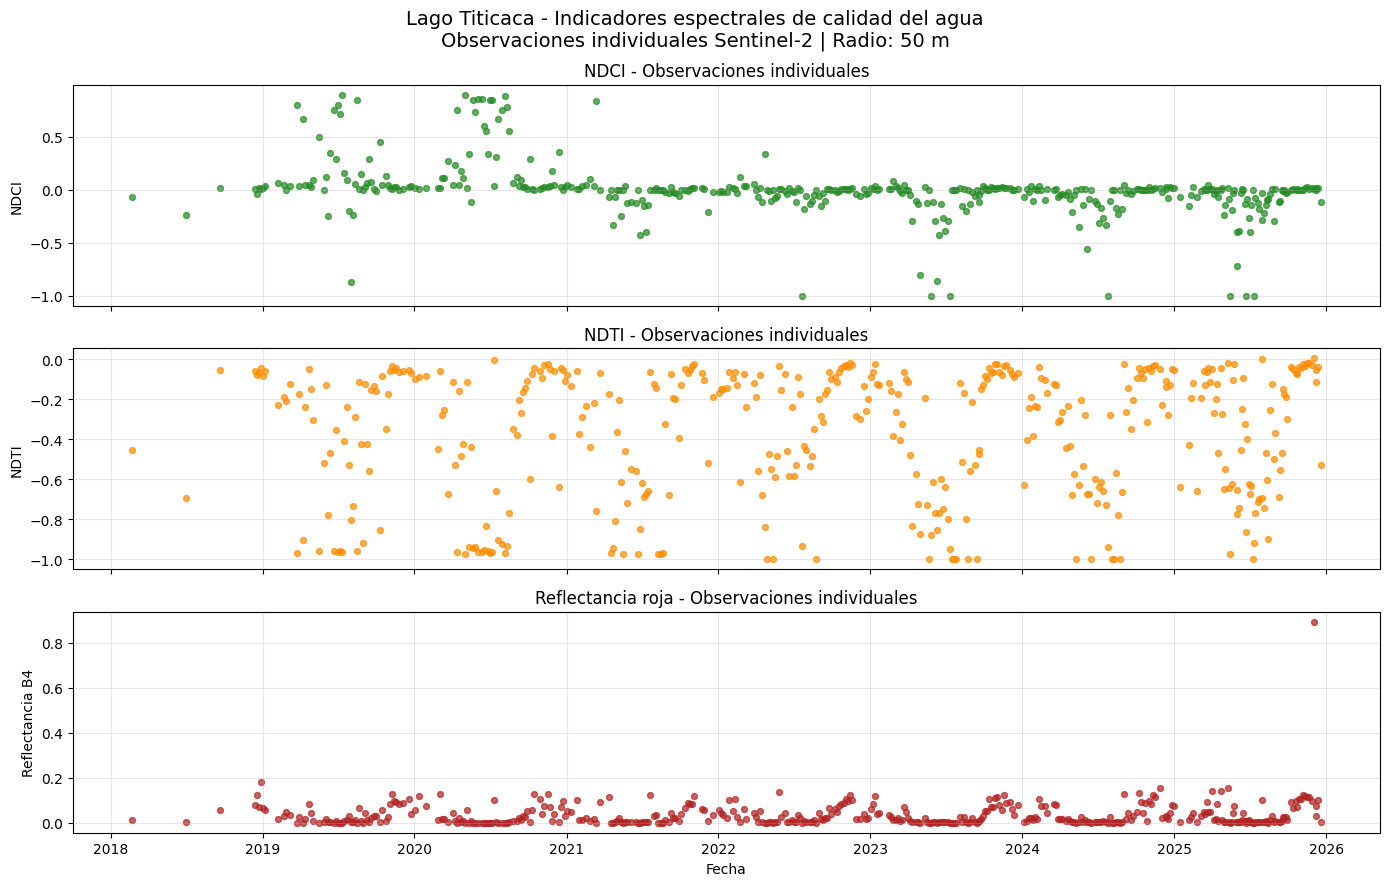

In [75]:
# ============================================================
# Series temporales con observaciones individuales
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True
)

# ============================================================
# Panel 1. NDCI
# ============================================================

axes[0].scatter(
    df_individual["date"],
    df_individual["NDCI"],
    color="forestgreen",
    s=18,
    alpha=0.7
)

axes[0].set_ylabel("NDCI")
axes[0].set_title(
    "NDCI - Observaciones individuales"
)
axes[0].grid(alpha=0.3)


# ============================================================
# Panel 2. NDTI
# ============================================================

axes[1].scatter(
    df_individual["date"],
    df_individual["NDTI"],
    color="darkorange",
    s=18,
    alpha=0.7
)

axes[1].set_ylabel("NDTI")
axes[1].set_title(
    "NDTI - Observaciones individuales"
)
axes[1].grid(alpha=0.3)


# ============================================================
# Panel 3. Reflectancia roja
# ============================================================

axes[2].scatter(
    df_individual["date"],
    df_individual["B4"],
    color="firebrick",
    s=18,
    alpha=0.7
)

axes[2].set_ylabel("Reflectancia B4")
axes[2].set_title(
    "Reflectancia roja - Observaciones individuales"
)

axes[2].set_xlabel("Fecha")
axes[2].grid(alpha=0.3)


# ============================================================
# Título general
# ============================================================

fig.suptitle(
    "Lago Titicaca - Indicadores espectrales de calidad del agua\n"
    f"Observaciones individuales Sentinel-2 | "
    f"Radio: {SAMPLE_RADIUS_M} m",
    fontsize=14
)

plt.tight_layout()
plt.show()

### De las observaciones individuales a los compuestos mensuales

Acabamos de construir una serie temporal utilizando las fechas individuales de adquisición de Sentinel-2. Esta serie permite observar la variabilidad espectral entre observaciones, pero también presenta algunas limitaciones:

- Las observaciones no están distribuidas uniformemente en el tiempo.
- Algunos meses tienen más imágenes válidas que otros.
- Pueden existir valores extremos asociados con condiciones atmosféricas residuales o variabilidad de corto plazo.

Para facilitar la interpretación, ahora construiremos **compuestos mensuales mediante la mediana temporal de las bandas espectrales**.

### ¿Qué haremos?

Para cada mes del período seleccionado:

1. Seleccionaremos las imágenes Sentinel-2 disponibles y eliminaremos los píxeles afectados por nubes y sombras.
2. Calcularemos la mediana temporal de las bandas espectrales.
3. Identificaremos el agua mediante **MNDWI > 0**.
4. Calcularemos los indicadores **NDCI, NDTI y reflectancia roja (B4)**.
5. Extraeremos la **mediana espacial de los píxeles válidos dentro de un radio de 50 m** alrededor del punto de interés.

Los índices se calcularán utilizando las mismas expresiones empleadas anteriormente en el ejercicio.

In [76]:
# ============================================================
# Construir serie mensual de indicadores Sentinel-2
# ============================================================

# Utilizamos las variables ya definidas:
# s2_ts          = colección Sentinel-2
# sample_area    = área circular de muestreo
# SAMPLE_RADIUS_M = radio de muestreo


# ============================================================
# Función: calcular indicadores para cada mes
# ============================================================

def calculate_monthly_indices(month_offset):

    # --------------------------------------------
    # Fechas del mes
    # --------------------------------------------

    start = ee.Date(START_TS).advance(
        ee.Number(month_offset),
        "month"
    )

    end = start.advance(1, "month")

    # Seleccionar observaciones del mes
    monthly_images = s2_ts.filterDate(start, end)

    n_images = monthly_images.size()

    # --------------------------------------------
    # Compuesto mensual Sentinel-2
    # --------------------------------------------

    bands = ["B3", "B4", "B5", "B11"]

    # Imagen vacía para meses sin observaciones
    empty_image = (
        ee.Image.constant([0, 0, 0, 0])
        .rename(bands)
        .updateMask(ee.Image.constant(0))
    )

    # Mediana temporal de reflectancia
    composite = ee.Image(
        ee.Algorithms.If(
            n_images.gt(0),
            monthly_images.median().select(bands),
            empty_image
        )
    ).multiply(0.0001)

    # --------------------------------------------
    # MNDWI: identificar agua
    # --------------------------------------------

    mndwi_month = (
        composite
        .normalizedDifference(["B3", "B11"])
        .rename("MNDWI")
    )

    water_month = mndwi_month.gt(0)

    # --------------------------------------------
    # NDCI: proxy de clorofila-a
    # --------------------------------------------

    ndci_month = (
        composite
        .normalizedDifference(["B5", "B4"])
        .rename("NDCI")
        .updateMask(water_month)
    )

    # --------------------------------------------
    # NDTI: proxy de turbidez
    # --------------------------------------------

    ndti_month = (
        composite
        .normalizedDifference(["B4", "B3"])
        .rename("NDTI")
        .updateMask(water_month)
    )

    # --------------------------------------------
    # Reflectancia roja B4
    # --------------------------------------------

    red_month = (
        composite
        .select("B4")
        .rename("B4")
        .updateMask(water_month)
    )

    # --------------------------------------------
    # Combinar indicadores
    # --------------------------------------------

    indices = ee.Image.cat([
        mndwi_month,
        ndci_month,
        ndti_month,
        red_month
    ])

    # ========================================================
    # Extraer mediana espacial dentro del área de muestreo
    # ========================================================

    values = indices.reduceRegion(
        reducer=ee.Reducer.median(),
        geometry=sample_area,
        scale=20,
        maxPixels=1e6,
        tileScale=4
    )

    # ========================================================
    # Contar píxeles válidos de agua
    # ========================================================

    pixel_count = (
        indices
        .select("NDCI")
        .reduceRegion(
            reducer=ee.Reducer.count(),
            geometry=sample_area,
            scale=20,
            maxPixels=1e6,
            tileScale=4
        )
        .get("NDCI")
    )

    # --------------------------------------------
    # Crear registro mensual
    # --------------------------------------------

    return ee.Feature(
        None,
        ee.Dictionary(values).combine(
            ee.Dictionary({
                "date": start.format("YYYY-MM-dd"),
                "n_images": n_images,
                "n_valid_pixels": pixel_count
            }),
            True
        )
    )


# ============================================================
# Construir la serie mensual
# ============================================================

n_months = len(monthly_dates_ts)

monthly_features = ee.FeatureCollection(
    ee.List.sequence(0, n_months - 1)
    .map(calculate_monthly_indices)
)

# Descargar resultados a Python
records_ts = [
    feature["properties"]
    for feature in monthly_features.getInfo()["features"]
]


# ============================================================
# Organizar resultados en Pandas
# ============================================================

df_quality_ts = (
    pd.DataFrame(records_ts)
    .reindex(
        columns=[
            "date",
            "n_images",
            "n_valid_pixels",
            "MNDWI",
            "NDCI",
            "NDTI",
            "B4"
        ]
    )
)

df_quality_ts["date"] = pd.to_datetime(
    df_quality_ts["date"]
)

for column in ["MNDWI", "NDCI", "NDTI", "B4"]:
    df_quality_ts[column] = pd.to_numeric(
        df_quality_ts[column],
        errors="coerce"
    )

df_quality_ts["n_valid_pixels"] = (
    pd.to_numeric(
        df_quality_ts["n_valid_pixels"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
)

df_quality_ts = (
    df_quality_ts
    .sort_values("date")
    .reset_index(drop=True)
)


# ============================================================
# Resumen de resultados
# ============================================================

print("Serie temporal mensual calculada.")
print("Número de meses:", len(df_quality_ts))

print(
    "Meses con indicadores válidos:",
    df_quality_ts["NDCI"].notna().sum()
)

print(
    "Radio de muestreo:",
    SAMPLE_RADIUS_M,
    "metros"
)

display(df_quality_ts)

Serie temporal mensual calculada.
Número de meses: 96
Meses con indicadores válidos: 88
Radio de muestreo: 50 metros


,date,n_images,n_valid_pixels,MNDWI,NDCI,NDTI,B4
0,2018-01-01,0,0,NaN,NaN,NaN,NaN
1,2018-02-01,1,21,0.689922,-0.072072,-0.458128,0.01170
2,2018-03-01,0,0,NaN,NaN,NaN,NaN
3,2018-04-01,0,0,NaN,NaN,NaN,NaN
4,2018-05-01,0,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
91,2025-08-01,8,21,0.512605,-0.195122,-0.478723,0.00505
92,2025-09-01,9,21,0.145422,-0.063492,-0.292308,0.00900
93,2025-10-01,8,21,0.135845,-0.002215,-0.040881,0.09080
94,2025-11-01,9,21,0.065492,0.018127,-0.028819,0.11245


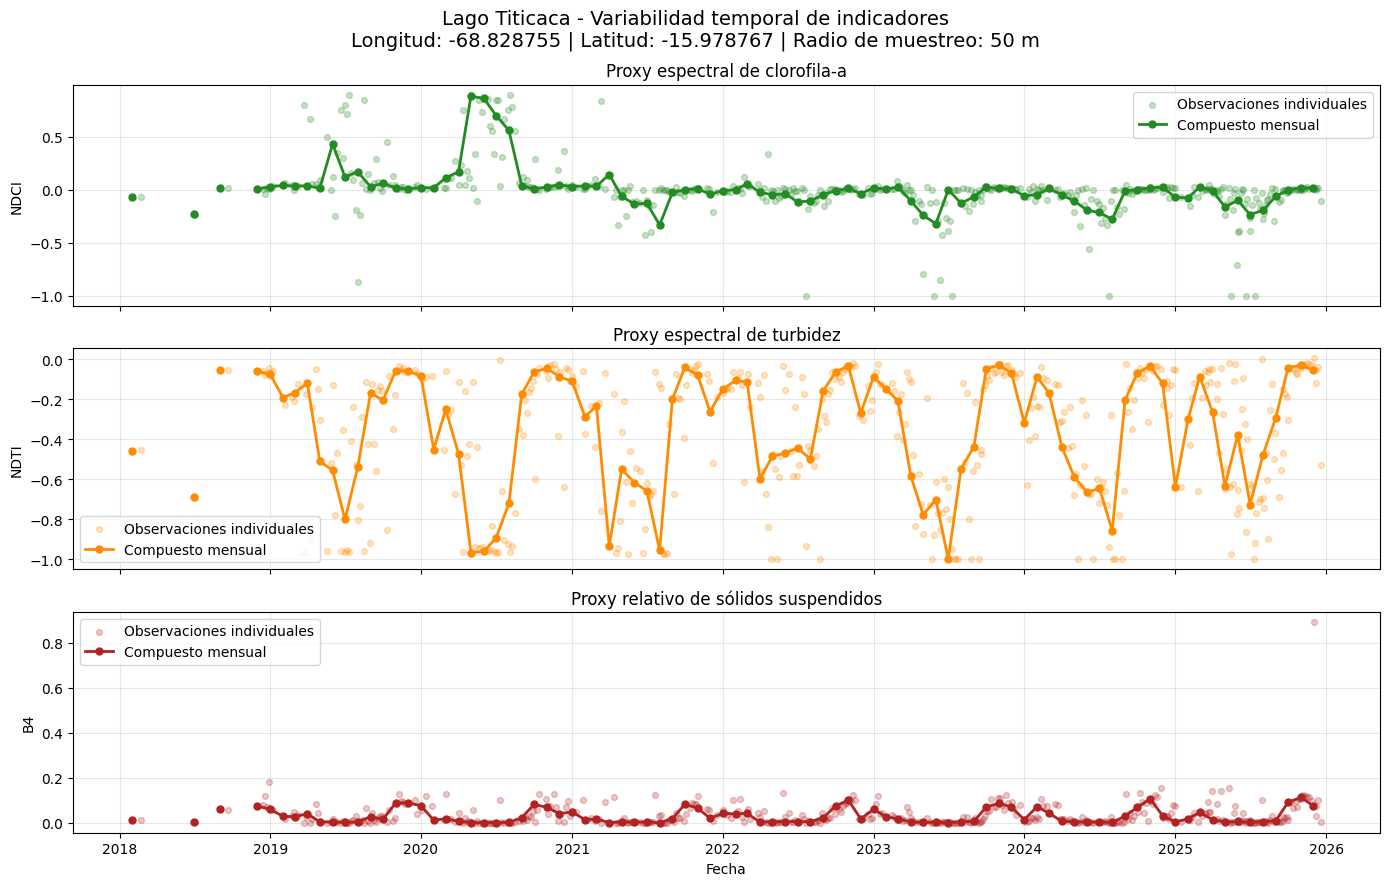

In [77]:
# ============================================================
# Comparación de observaciones individuales y compuestos
# mensuales de indicadores de calidad del agua
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True
)

# Configuración de indicadores
indicators = [
    ("NDCI", "forestgreen", "Proxy espectral de clorofila-a"),
    ("NDTI", "darkorange", "Proxy espectral de turbidez"),
    ("B4", "firebrick", "Proxy relativo de sólidos suspendidos")
]

# ============================================================
# Construir los tres paneles
# ============================================================

for ax, (indicator, color, title) in zip(axes, indicators):

    # Observaciones individuales Sentinel-2
    ax.scatter(
        df_individual["date"],
        df_individual[indicator],
        color=color,
        s=18,
        alpha=0.25,
        label="Observaciones individuales",
        zorder=2
    )

    # Compuestos mensuales
    ax.plot(
        df_quality_ts["date"],
        df_quality_ts[indicator],
        color=color,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Compuesto mensual",
        zorder=3
    )

    ax.set_ylabel(indicator)
    ax.set_title(title)

    ax.grid(alpha=0.3)
    ax.legend(loc="best")


# ============================================================
# Configuración general
# ============================================================

axes[2].set_xlabel("Fecha")

fig.suptitle(
    "Lago Titicaca - Variabilidad temporal de indicadores\n"
    f"Longitud: {LON} | Latitud: {LAT} | "
    f"Radio de muestreo: {SAMPLE_RADIUS_M} m",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Interpretemos las series temporales

Ahora tenemos tres indicadores espectrales de calidad del agua calculados para un punto de interés del Lago Titicaca, utilizando observaciones de Sentinel-2 durante un período de dos años.

Para cada indicador podemos comparar dos tipos de información:

- **Observaciones individuales:** valores obtenidos para cada fecha de adquisición de Sentinel-2, calculados como la mediana espacial de los píxeles válidos dentro del área de muestreo.
- **Compuestos mensuales:** valores calculados a partir de la mediana temporal de las reflectancias disponibles durante cada mes y posteriormente resumidos mediante la mediana espacial.

Esta comparación permite explorar la **variabilidad temporal de los indicadores** y comprender cómo la agregación mensual puede facilitar la identificación de patrones generales, aunque también puede suavizar fluctuaciones de corto plazo.

### Preguntas

1. **Variabilidad temporal:** ¿los indicadores permanecen relativamente estables o presentan fluctuaciones importantes? ¿Qué diferencias observas entre las mediciones individuales y los compuestos mensuales?

2. **Agregación temporal:** ¿qué cambios se observan al pasar de las observaciones individuales a los compuestos mensuales? ¿Qué información se conserva y cuál podría perderse?

3. **Estacionalidad:** ¿puedes identificar períodos del año en los que los indicadores tienden a aumentar o disminuir? ¿Se repiten estos patrones entre los dos años analizados?

4. **Procesos ambientales:** ¿qué procesos podrían explicar las variaciones observadas? Considera las precipitaciones, los aportes de sedimentos, la actividad del fitoplancton y los procesos de mezcla del agua.

### Ejercicio adicional: comparación entre sectores del lago

Modifica las coordenadas del punto de interés y repite el análisis, manteniendo el mismo período temporal y radio de muestreo.

Compara, por ejemplo:

- **Bahía de Cohana:** un sector costero influenciado por aportes continentales y actividades humanas.
- **Aguas abiertas del Lago Menor:** un sector más alejado de las principales zonas de influencia costera.

**¿Los dos sectores presentan el mismo comportamiento temporal de NDCI, NDTI y reflectancia roja?**

¿Qué diferencias identificas en la magnitud y variabilidad de los indicadores? ¿Qué procesos hidrológicos, ambientales o antrópicos podrían explicar estos contrastes?

# 12. Productos derivados MODIS Aqua

Ahora utilizaremos productos que ya han sido procesados mediante
algoritmos bio-ópticos y térmicos.

Utilizaremos:

### Clorofila-a

`chlor_a`

Unidad:

**mg/m³**

### Temperatura superficial

`sst`

Unidad:

**°C**

Utilizaremos exactamente el mismo período empleado para Sentinel-2 para la inspección visual del producto:

**mayo–junio de 2025**

y calcularemos la mediana temporal.

In [78]:
# ============================================================
# Cargar MODIS Aqua
# ============================================================

modis = (
    ee.ImageCollection(
        "NASA/OCEANDATA/MODIS-Aqua/L3SMI"
    )
    .filterDate(
        START_DATE,
        END_DATE
    )
)

print(
    "Número de imágenes MODIS:",
    modis.size().getInfo()
)

Número de imágenes MODIS: 61


In [79]:
# ============================================================
# Crear compuestos MODIS
# ============================================================

modis_chl = (
    modis
    .select("chlor_a")
    .median()
    .clip(roi)
)

modis_sst = (
    modis
    .select("sst")
    .median()
    .clip(roi)
)

print(
    "Compuestos MODIS preparados."
)

Compuestos MODIS preparados.


In [80]:
# ============================================================
# Visualizar clorofila-a MODIS
# ============================================================

chl_vis = {
    "min": 0,
    "max": 30,
    "palette": [
        "440154",
        "3b528b",
        "21918c",
        "5ec962",
        "fde725"
    ]
}

Map_chl = geemap.Map()

Map_chl.centerObject(
    roi,
    9
)

Map_chl.add_basemap(
    "Esri.WorldImagery"
)

Map_chl.addLayer(
    modis_chl,
    chl_vis,
    "MODIS chlor_a"
)

# ============================================================
# Agregar barra de colores
# ============================================================

Map_chl.add_colorbar(
    chl_vis,
    label="Clorofila-a (mg/m³)",
    orientation="horizontal",
    position="bottomright",
    layer_name="MODIS chlor_a"
)

Map_chl

Map(center=[-15.900307221437474, -69.3388988040462], controls=(WidgetControl(options=['position', 'transparent…

### Observa la diferencia de escala

Recuerda:

Sentinel-2:

**10–20 m**

MODIS L3SMI:

**~4.6 km**

### Preguntas

1. ¿Cuánto detalle espacial se perdió?

2. ¿Puedes distinguir pequeñas bahías?

3. ¿Es posible identificar detalles costeros como con Sentinel-2?

4. ¿Qué ventaja tiene entonces MODIS?

Una ventaja importante es su alta frecuencia temporal y la disponibilidad
directa de productos derivados.

In [81]:
# ============================================================
# Visualizar temperatura superficial MODIS
# ============================================================

sst_vis = {
    "min": 5,
    "max": 20,
    "palette": [
        "313695",
        "4575b4",
        "74add1",
        "fee090",
        "f46d43",
        "a50026"
    ]
}

Map_sst = geemap.Map()

Map_sst.centerObject(
    roi,
    9
)

Map_sst.add_basemap(
    "Esri.WorldImagery"
)

Map_sst.addLayer(
    modis_sst,
    sst_vis,
    "MODIS SST"
)

# ============================================================
# Agregar barra de colores
# ============================================================

Map_sst.add_colorbar(
    sst_vis,
    label="Temperatura superficial (°C)",
    orientation="horizontal",
    position="bottomright",
    layer_name="MODIS SST"
)

Map_sst

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Preguntas

1. ¿La temperatura es homogénea en todo el sector?

2. ¿Se observan diferencias entre zonas costeras y aguas abiertas?

3. ¿Qué procesos podrían producir diferencias de temperatura?

Por ejemplo:

- profundidad;
- mezcla del agua;
- radiación solar;
- viento;
- intercambio con tributarios.

---

### Una diferencia importante

Sentinel-2 no posee una banda térmica.

Por tanto:

**Sentinel-2 → gran detalle espacial en información óptica**

**MODIS → permite incorporar temperatura superficial**

## 12.1. Variabilidad temporal de clorofila-a y temperatura superficial

Hasta ahora hemos explorado la distribución espacial de la clorofila-a
y la temperatura superficial del Lago Titicaca mediante compuestos
temporales de MODIS Aqua.

Sin embargo, MODIS también proporciona **productos diarios**, que
permiten analizar cómo cambian estas variables a lo largo del tiempo.

En esta sección construiremos dos series temporales:

- **Clorofila-a (`chlor_a`):** concentración estimada en mg/m³.
- **Temperatura superficial (`sst`):** temperatura estimada en °C.

In [82]:
# ============================================================
# Cargar MODIS Aqua para la serie temporal diaria
# ============================================================

# Resolución espacial nominal del producto (metros)
MODIS_SCALE = 4616

# Colección MODIS Aqua L3SMI
modis_ts = (
    ee.ImageCollection("NASA/OCEANDATA/MODIS-Aqua/L3SMI")
    .filterDate(START_TS, END_TS)
    .filterBounds(point_ts)
    .select(["chlor_a", "sst"])
    .sort("system:time_start")
)

# ============================================================
# Verificar disponibilidad de imágenes
# ============================================================

n_modis = modis_ts.size().getInfo()

print("Período solicitado:", START_TS, "a", END_TS)
print("Longitud:", LON)
print("Latitud:", LAT)
print("Resolución espacial:", MODIS_SCALE, "m")
print("Número de imágenes MODIS:", n_modis)

if n_modis == 0:
    raise ValueError(
        "No hay imágenes MODIS disponibles "
        "para el período seleccionado."
    )

# Primera y última observación disponible
modis_dates = pd.to_datetime(
    modis_ts.aggregate_array(
        "system:time_start"
    ).getInfo(),
    unit="ms",
    utc=True
)

print(
    "Primera imagen:",
    modis_dates.min().strftime("%Y-%m-%d")
)

print(
    "Última imagen:",
    modis_dates.max().strftime("%Y-%m-%d")
)

Período solicitado: 2018-01-01 a 2026-01-01
Longitud: -68.828755
Latitud: -15.978767
Resolución espacial: 4616 m
Número de imágenes MODIS: 2783
Primera imagen: 2018-01-01
Última imagen: 2025-11-30


In [83]:
# ============================================================
# Extraer clorofila-a y temperatura de cada imagen MODIS
# ============================================================

def extract_modis_values(image):

    # --------------------------------------------
    # Extraer valores en el punto de interés
    # --------------------------------------------

    values = image.select(
        ["chlor_a", "sst"]
    ).reduceRegion(
        reducer=ee.Reducer.first(),
        geometry=point_ts,
        scale=MODIS_SCALE,
        maxPixels=1e6
    )

    # --------------------------------------------
    # Crear registro individual
    # --------------------------------------------

    return ee.Feature(
        None,
        {
            "time_ms": image.get("system:time_start"),
            "chlor_a": values.get("chlor_a"),
            "sst": values.get("sst")
        }
    )


# ============================================================
# Procesar y descargar resultados por bloques anuales
# ============================================================

start_dt = pd.Timestamp(START_TS)
end_dt = pd.Timestamp(END_TS)

# Límites anuales dentro del período seleccionado
year_boundaries = pd.date_range(
    start=start_dt,
    end=end_dt,
    freq="YS"
)

boundaries = sorted(set(
    [start_dt, end_dt] + list(year_boundaries)
))

modis_records = []

for block_start, block_end in zip(
    boundaries[:-1],
    boundaries[1:]
):

    # Seleccionar las imágenes del bloque
    subset = modis_ts.filterDate(
        block_start.strftime("%Y-%m-%d"),
        block_end.strftime("%Y-%m-%d")
    )

    n_subset = subset.size().getInfo()

    if n_subset == 0:
        continue

    # Convertir imágenes a registros con valores
    image_list = subset.toList(n_subset)

    features = ee.FeatureCollection(
        ee.List.sequence(0, n_subset - 1).map(
            lambda i: extract_modis_values(
                ee.Image(image_list.get(i))
            )
        )
    )

    # Descargar registros del bloque
    block_records = [
        feature["properties"]
        for feature in features.getInfo()["features"]
    ]

    modis_records.extend(block_records)

    print(
        f"{block_start:%Y-%m-%d} a "
        f"{block_end:%Y-%m-%d}: "
        f"{len(block_records)} imágenes procesadas"
    )


# ============================================================
# Organizar resultados en Pandas
# ============================================================

df_modis_daily = (
    pd.DataFrame(modis_records)
    .reindex(
        columns=[
            "time_ms",
            "chlor_a",
            "sst"
        ]
    )
)

# Convertir tiempo a fecha
df_modis_daily["date"] = pd.to_datetime(
    df_modis_daily["time_ms"],
    unit="ms",
    utc=True
).dt.tz_localize(None)

# Convertir valores a numéricos
for column in ["chlor_a", "sst"]:
    df_modis_daily[column] = pd.to_numeric(
        df_modis_daily[column],
        errors="coerce"
    )

# Ordenar cronológicamente
df_modis_daily = (
    df_modis_daily
    .sort_values("date")
    .reset_index(drop=True)
)


# ============================================================
# Resumen de disponibilidad
# ============================================================

print("\nSerie temporal MODIS calculada.")
print("Número de imágenes:", len(df_modis_daily))

print(
    "Observaciones válidas de clorofila-a:",
    df_modis_daily["chlor_a"].notna().sum()
)

print(
    "Observaciones válidas de temperatura:",
    df_modis_daily["sst"].notna().sum()
)

print(
    "Observaciones con ambas variables:",
    df_modis_daily[
        ["chlor_a", "sst"]
    ].notna().all(axis=1).sum()
)

display(df_modis_daily.head(10))

print("...")

display(df_modis_daily.tail(10))

2018-01-01 a 2019-01-01: 365 imágenes procesadas
2019-01-01 a 2020-01-01: 365 imágenes procesadas
2020-01-01 a 2021-01-01: 366 imágenes procesadas
2021-01-01 a 2022-01-01: 275 imágenes procesadas
2022-01-01 a 2023-01-01: 351 imágenes procesadas
2023-01-01 a 2024-01-01: 365 imágenes procesadas
2024-01-01 a 2025-01-01: 366 imágenes procesadas
2025-01-01 a 2026-01-01: 330 imágenes procesadas

Serie temporal MODIS calculada.
Número de imágenes: 2783
Observaciones válidas de clorofila-a: 679
Observaciones válidas de temperatura: 1010
Observaciones con ambas variables: 656


,time_ms,chlor_a,sst,date
0,1514764801000,NaN,NaN,2018-01-01 00:00:01
1,1514853301000,NaN,NaN,2018-01-02 00:35:01
2,1514940601000,NaN,NaN,2018-01-03 00:50:01
3,1515025501000,NaN,NaN,2018-01-04 00:25:01
4,1515112500000,NaN,NaN,2018-01-05 00:35:00
5,1515197701000,NaN,NaN,2018-01-06 00:15:01
6,1515286201000,NaN,NaN,2018-01-07 00:50:01
7,1515369900000,NaN,NaN,2018-01-08 00:05:00
8,1515456601000,NaN,NaN,2018-01-09 00:10:01
9,1515542400000,NaN,NaN,2018-01-10 00:00:00


...


,time_ms,chlor_a,sst,date
2773,1763685600895,NaN,NaN,2025-11-21 00:40:00.895
2774,1763771100641,11.556798,16.824999,2025-11-22 00:25:00.641
2775,1763857201573,NaN,NaN,2025-11-23 00:20:01.573
2776,1763942701319,NaN,NaN,2025-11-24 00:05:01.319
2777,1764028800772,NaN,NaN,2025-11-25 00:00:00.772
2778,1764117300527,NaN,NaN,2025-11-26 00:35:00.527
2779,1764202801752,NaN,NaN,2025-11-27 00:20:01.752
2780,1764288901200,NaN,NaN,2025-11-28 00:15:01.200
2781,1764374400943,NaN,NaN,2025-11-29 00:00:00.943
2782,1764462900705,NaN,NaN,2025-11-30 00:35:00.705


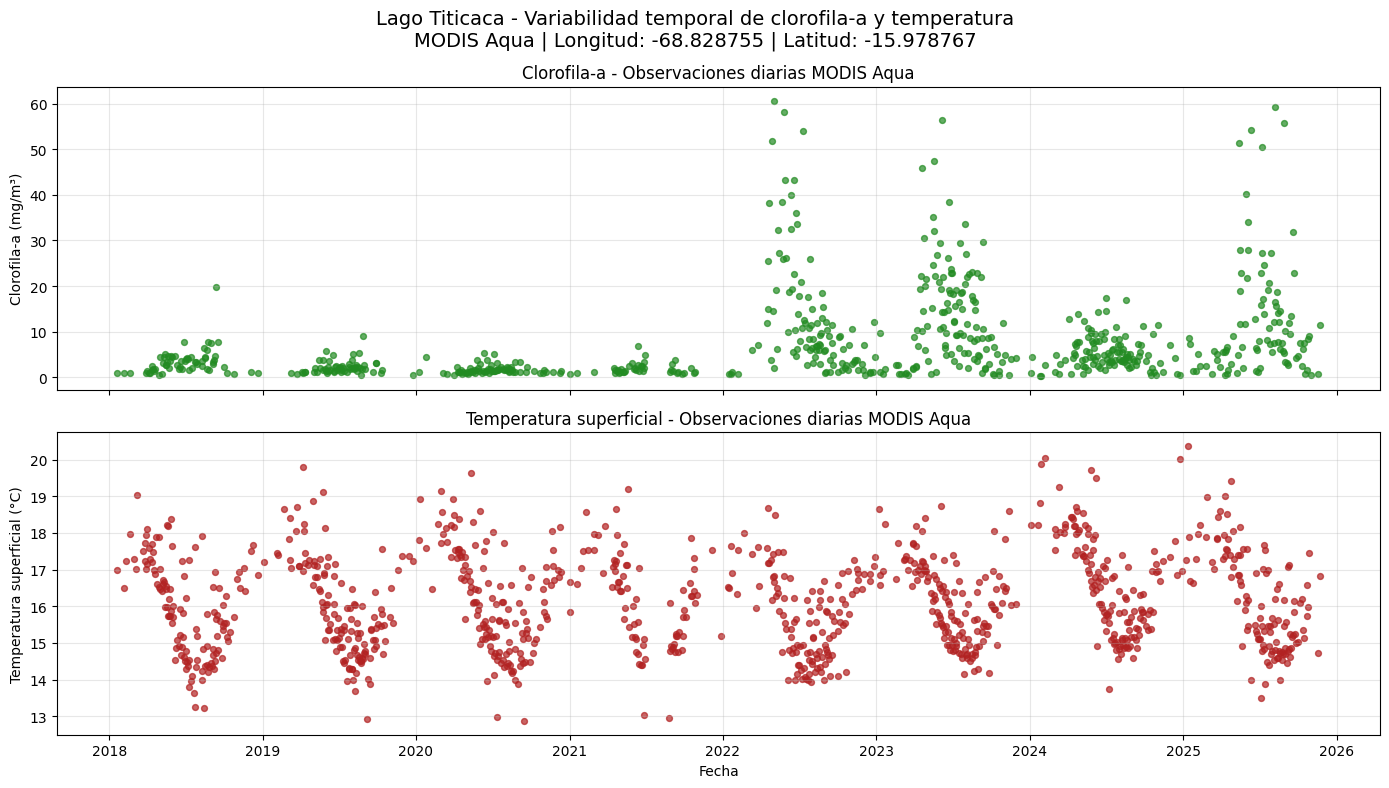

In [84]:
# ============================================================
# Series temporales diarias MODIS Aqua
# Clorofila-a y temperatura superficial
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# ============================================================
# Panel 1. Clorofila-a
# ============================================================

axes[0].scatter(
    df_modis_daily["date"],
    df_modis_daily["chlor_a"],
    color="forestgreen",
    s=18,
    alpha=0.7
)

axes[0].set_ylabel("Clorofila-a (mg/m³)")

axes[0].set_title(
    "Clorofila-a - Observaciones diarias MODIS Aqua"
)

axes[0].grid(alpha=0.3)


# ============================================================
# Panel 2. Temperatura superficial
# ============================================================

axes[1].scatter(
    df_modis_daily["date"],
    df_modis_daily["sst"],
    color="firebrick",
    s=18,
    alpha=0.7
)

axes[1].set_ylabel("Temperatura superficial (°C)")

axes[1].set_title(
    "Temperatura superficial - Observaciones diarias MODIS Aqua"
)

axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.3)


# ============================================================
# Título general
# ============================================================

fig.suptitle(
    "Lago Titicaca - Variabilidad temporal de clorofila-a "
    "y temperatura\n"
    f"MODIS Aqua | Longitud: {LON} | Latitud: {LAT}",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Interpretemos las observaciones diarias de MODIS Aqua

A diferencia de los índices espectrales calculados con Sentinel-2,
MODIS proporciona productos derivados mediante algoritmos
bio-ópticos y térmicos:

- **Clorofila-a:** concentración estimada en mg/m³.
- **Temperatura superficial:** temperatura estimada en °C.

### Preguntas

1. **Disponibilidad de datos:** ¿cuántas observaciones válidas
   encontramos para clorofila-a y temperatura? ¿Ambas variables
   tienen información disponible en las mismas fechas?

2. **Variabilidad temporal:** ¿las variables presentan cambios
   importantes durante el período? ¿Se observan valores extremos?

3. **Estacionalidad:** ¿puedes identificar períodos de temperaturas
   más altas y más bajas? ¿Se repiten estos patrones entre años?

4. **Clorofila-a:** ¿los valores presentan un comportamiento
   estacional o muestran variaciones más irregulares?

### De las observaciones diarias a los compuestos mensuales MODIS

Ahora construiremos **series mensuales mediante la mediana
de las observaciones diarias válidas**.

In [85]:
# ============================================================
# Agregación mensual de MODIS Aqua
# Clorofila-a y temperatura superficial
# ============================================================

# ============================================================
# Preparar fechas mensuales
# ============================================================

# Crear una copia del DataFrame diario
df_modis = df_modis_daily.copy()

# Identificar el mes de cada observación
df_modis["month"] = (
    df_modis["date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# ============================================================
# Calcular medianas mensuales
# ============================================================

df_modis_monthly = (
    df_modis
    .groupby("month")
    .agg(
        chlor_a=("chlor_a", "median"),
        sst=("sst", "median"),
        n_chlor_a=("chlor_a", "count"),
        n_sst=("sst", "count")
    )
)

# ============================================================
# Mantener todos los meses del período
# ============================================================

all_months = pd.date_range(
    start=pd.Timestamp(START_TS).replace(day=1),
    end=(
        pd.Timestamp(END_TS) - pd.Timedelta(days=1)
    ).replace(day=1),
    freq="MS"
)

df_modis_monthly = (
    df_modis_monthly
    .reindex(all_months)
    .rename_axis("date")
    .reset_index()
)

# Meses sin observaciones válidas
df_modis_monthly["n_chlor_a"] = (
    df_modis_monthly["n_chlor_a"]
    .fillna(0)
    .astype(int)
)

df_modis_monthly["n_sst"] = (
    df_modis_monthly["n_sst"]
    .fillna(0)
    .astype(int)
)

# ============================================================
# Resumen de resultados
# ============================================================

print("Agregación mensual MODIS completada.")

print(
    "Número de meses:",
    len(df_modis_monthly)
)

print(
    "Meses con clorofila-a válida:",
    df_modis_monthly["chlor_a"].notna().sum()
)

print(
    "Meses con temperatura válida:",
    df_modis_monthly["sst"].notna().sum()
)

print(
    "Observaciones diarias válidas de clorofila-a:",
    df_modis_monthly["n_chlor_a"].sum()
)

print(
    "Observaciones diarias válidas de temperatura:",
    df_modis_monthly["n_sst"].sum()
)

display(df_modis_monthly.head(10))

print("...")

display(df_modis_monthly.tail(10))

Agregación mensual MODIS completada.
Número de meses: 96
Meses con clorofila-a válida: 85
Meses con temperatura válida: 92
Observaciones diarias válidas de clorofila-a: 679
Observaciones diarias válidas de temperatura: 1010


,date,chlor_a,sst,n_chlor_a,n_sst
0,2018-01-01,0.867580,16.980000,1,1
1,2018-02-01,0.971853,17.267500,2,4
2,2018-03-01,1.031650,17.605000,1,8
3,2018-04-01,1.309310,17.250000,9,12
4,2018-05-01,3.638246,16.469999,13,21
5,2018-06-01,2.575188,15.165000,7,15
6,2018-07-01,3.422238,14.489999,10,18
7,2018-08-01,4.309766,14.370000,9,11
8,2018-09-01,4.620214,15.270000,7,20
9,2018-10-01,0.929416,15.549999,3,7


...


,date,chlor_a,sst,n_chlor_a,n_sst
86,2025-03-01,3.821002,17.855000,5,6
87,2025-04-01,5.435239,17.555000,9,13
88,2025-05-01,11.699678,16.780000,11,14
89,2025-06-01,10.456846,15.344999,10,11
90,2025-07-01,17.265303,15.315000,15,24
91,2025-08-01,12.077756,14.795000,16,19
92,2025-09-01,9.467261,15.187500,9,16
93,2025-10-01,6.180237,15.990000,9,9
94,2025-11-01,0.705965,15.772499,3,2
95,2025-12-01,NaN,NaN,0,0


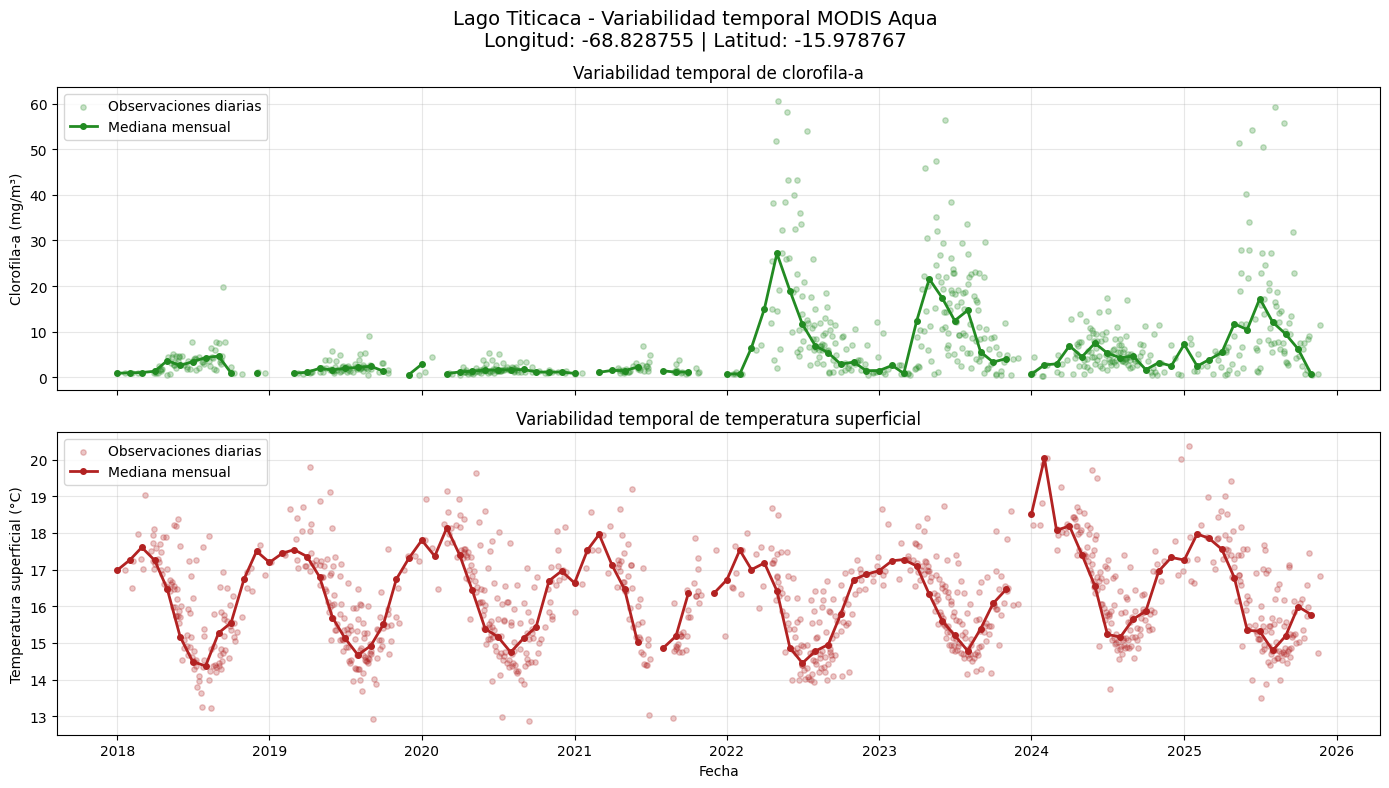

In [86]:
# ============================================================
# Comparación de observaciones diarias y medianas mensuales
# MODIS Aqua
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# ============================================================
# Panel 1. Clorofila-a
# ============================================================

# Observaciones diarias
axes[0].scatter(
    df_modis_daily["date"],
    df_modis_daily["chlor_a"],
    color="forestgreen",
    s=15,
    alpha=0.25,
    label="Observaciones diarias"
)

# Medianas mensuales
axes[0].plot(
    df_modis_monthly["date"],
    df_modis_monthly["chlor_a"],
    color="forestgreen",
    marker="o",
    markersize=4,
    linewidth=2,
    label="Mediana mensual"
)

axes[0].set_ylabel("Clorofila-a (mg/m³)")

axes[0].set_title(
    "Variabilidad temporal de clorofila-a"
)

axes[0].grid(alpha=0.3)
axes[0].legend()


# ============================================================
# Panel 2. Temperatura superficial
# ============================================================

# Observaciones diarias
axes[1].scatter(
    df_modis_daily["date"],
    df_modis_daily["sst"],
    color="firebrick",
    s=15,
    alpha=0.25,
    label="Observaciones diarias"
)

# Medianas mensuales
axes[1].plot(
    df_modis_monthly["date"],
    df_modis_monthly["sst"],
    color="firebrick",
    marker="o",
    markersize=4,
    linewidth=2,
    label="Mediana mensual"
)

axes[1].set_ylabel("Temperatura superficial (°C)")

axes[1].set_title(
    "Variabilidad temporal de temperatura superficial"
)

axes[1].set_xlabel("Fecha")

axes[1].grid(alpha=0.3)
axes[1].legend()


# ============================================================
# Título general
# ============================================================

fig.suptitle(
    "Lago Titicaca - Variabilidad temporal MODIS Aqua\n"
    f"Longitud: {LON} | Latitud: {LAT}",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Interpretemos los compuestos mensuales MODIS

Ahora tenemos dos series temporales para el mismo punto
del Lago Titicaca:

- **Observaciones diarias:** valores disponibles de clorofila-a
  y temperatura superficial para cada fecha.
- **Medianas mensuales:** valores que resumen las observaciones
  válidas de cada mes.

La comparación permite reconocer patrones temporales generales
y evaluar cómo cambia la variabilidad al agregar las observaciones.

## 12.2. Clorofila-a con Sentinel-3 OLCI: Copernicus Marine

Ahora incorporaremos un tercer producto: **Copernicus Marine
Global Ocean Colour, derivado de Sentinel-3 OLCI**.

Este producto proporciona estimaciones de concentración de
clorofila-a mediante algoritmos bio-ópticos, con las siguientes
características:

- **Variable:** clorofila-a (`CHL`).
- **Unidad:** mg/m³.
- **Resolución espacial:** 300 m.
- **Resolución temporal:** mensual.

**Precaución:** aunque el producto proporciona concentraciones
estimadas en mg/m³, sus algoritmos fueron desarrollados
principalmente para ambientes marinos. Su aplicación al Lago
Titicaca requiere validación con observaciones de campo.

In [92]:
# ============================================================
# Copernicus Marine - Sentinel-3 OLCI
# Clorofila-a a 300 m
# ============================================================

OLCI_COLLECTION = (
    "COPERNICUS/MARINE/OC_GLO_BGC/PLANKTON_OLCI_300M"
)

OLCI_SCALE = 300

# Cargar colección completa
olci_all = ee.ImageCollection(OLCI_COLLECTION)

# ============================================================
# Función para seleccionar clorofila-a sobre agua
# ============================================================

def prepare_olci(image):

    water_mask = image.select("flags").eq(0)

    chl = (
        image
        .select("CHL")
        .updateMask(water_mask)
        .rename("CHL")
    )

    return chl.copyProperties(
        image,
        ["system:time_start"]
    )


# ============================================================
# Colección preparada
# ============================================================

olci_prepared = olci_all.map(prepare_olci)

print("Colección Copernicus Marine OLCI cargada.")
print("Resolución espacial:", OLCI_SCALE, "m")
print("Resolución temporal: mensual")

Colección Copernicus Marine OLCI cargada.
Resolución espacial: 300 m
Resolución temporal: mensual


### Distribución espacial de clorofila-a: mayo–junio de 2025

Primero visualizaremos la distribución espacial de la clorofila-a
estimada mediante Sentinel-3 OLCI.

In [93]:
# ============================================================
# Visualizar clorofila-a Sentinel-3 OLCI
# Julio - Agosto 2025
# ============================================================

OLCI_MAP_START = "2025-05-01"
OLCI_MAP_END = "2025-07-01"

# Seleccionar los dos meses
olci_map_collection = (
    olci_prepared
    .filterDate(OLCI_MAP_START, OLCI_MAP_END)
)

print(
    "Número de productos mensuales:",
    olci_map_collection.size().getInfo()
)

# Mediana de julio y agosto
olci_chl_map = (
    olci_map_collection
    .median()
    .clip(lake_geometry)
)

# ============================================================
# Visualización: misma escala que MODIS
# ============================================================

olci_chl_vis = {
    "min": 0,
    "max": 30,
    "palette": [
        "440154",
        "3b528b",
        "21918c",
        "5ec962",
        "fde725"
    ]
}

Map_olci_chl = geemap.Map()

Map_olci_chl.centerObject(roi, 8)

Map_olci_chl.add_basemap(
    "Esri.WorldImagery"
)

Map_olci_chl.addLayer(
    olci_chl_map,
    olci_chl_vis,
    "Copernicus Marine OLCI - CHL"
)

# ============================================================
# Barra de colores
# ============================================================

Map_olci_chl.add_colorbar(
    olci_chl_vis,
    label="Clorofila-a (mg/m³)",
    orientation="horizontal",
    position="bottomright",
    layer_name="Copernicus Marine OLCI - CHL"
)

Map_olci_chl

Número de productos mensuales: 2


Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

### Serie temporal de clorofila-a con Copernicus Marine OLCI

Ahora construiremos una serie temporal de clorofila-a para
el mismo punto de interés utilizado con Sentinel-2 y MODIS Aqua.

Emplearemos las variables de coordenadas y fechas definidas
anteriormente en el notebook.

La colección utilizada comienza en marzo de 2025. Si el
período de análisis comienza antes de esa fecha, no tendremos
observaciones de este producto para los meses anteriores.

Los meses sin información válida no se interpretarán como
concentraciones iguales a cero.

In [94]:
# ============================================================
# Serie temporal nativa Copernicus Marine OLCI
# Clorofila-a mensual a 300 m
# ============================================================

olci_ts = (
    olci_prepared
    .filterDate(START_TS, END_TS)
    .filterBounds(point_ts)
    .sort("system:time_start")
)

n_olci = olci_ts.size().getInfo()

print("Período:", START_TS, "a", END_TS)
print("Productos mensuales disponibles:", n_olci)
print("Longitud:", LON)
print("Latitud:", LAT)

if n_olci == 0:
    raise ValueError(
        "No hay productos OLCI para el período seleccionado."
    )


# ============================================================
# Función de extracción por imagen
# ============================================================

def extract_olci_values(image):

    # Extraer el valor del píxel correspondiente al punto
    values = image.reduceRegion(
        reducer=ee.Reducer.first(),
        geometry=point_ts,
        scale=OLCI_SCALE,
        maxPixels=1e6
    )

    return ee.Feature(
        None,
        {
            "time_ms": image.get("system:time_start"),
            "chlor_a_olci": values.get("CHL")
        }
    )


# ============================================================
# Procesar todos los productos mensuales
# ============================================================

olci_list = olci_ts.toList(n_olci)

olci_features = ee.FeatureCollection(
    ee.List.sequence(0, n_olci - 1).map(
        lambda i: extract_olci_values(
            ee.Image(olci_list.get(i))
        )
    )
)

olci_records = [
    feature["properties"]
    for feature in olci_features.getInfo()["features"]
]


# ============================================================
# Organizar resultados en Pandas
# ============================================================

df_olci_native = (
    pd.DataFrame(olci_records)
    .reindex(
        columns=[
            "time_ms",
            "chlor_a_olci"
        ]
    )
)

# Convertir fechas
df_olci_native["date"] = pd.to_datetime(
    df_olci_native["time_ms"],
    unit="ms",
    utc=True
).dt.tz_localize(None)

# Convertir concentraciones a numéricas
df_olci_native["chlor_a_olci"] = pd.to_numeric(
    df_olci_native["chlor_a_olci"],
    errors="coerce"
)

# Ordenar temporalmente
df_olci_native = (
    df_olci_native
    .sort_values("date")
    .reset_index(drop=True)
)

# ============================================================
# Resumen
# ============================================================

print("Serie temporal OLCI calculada.")

print(
    "Productos mensuales:",
    len(df_olci_native)
)

print(
    "Meses con clorofila-a válida:",
    df_olci_native["chlor_a_olci"].notna().sum()
)

display(
    df_olci_native[
        ["date", "chlor_a_olci"]
    ]
)

Período: 2018-01-01 a 2026-01-01
Productos mensuales disponibles: 10
Longitud: -68.828755
Latitud: -15.978767
Serie temporal OLCI calculada.
Productos mensuales: 10
Meses con clorofila-a válida: 10


,date,chlor_a_olci
0,2025-03-01,4.553813
1,2025-04-01,4.545689
2,2025-05-01,5.687745
3,2025-06-01,5.809198
4,2025-07-01,6.830983
5,2025-08-01,6.755301
6,2025-09-01,6.021048
7,2025-10-01,6.741167
8,2025-11-01,5.563277
9,2025-12-01,8.506649


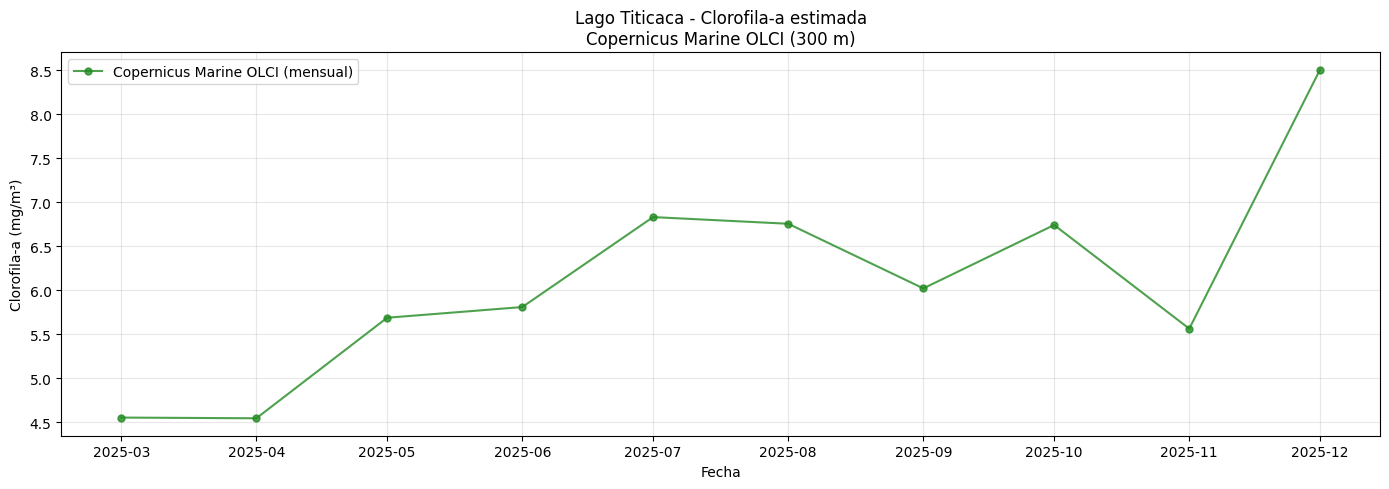

In [95]:
# ============================================================
# Serie temporal nativa de clorofila-a OLCI
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df_olci_native["date"],
    df_olci_native["chlor_a_olci"],
    color="forestgreen",
    marker="o",
    markersize=5,
    linewidth=1.5,
    alpha=0.8,
    linestyle="-",
    label="Copernicus Marine OLCI (mensual)"
)

plt.xlabel("Fecha")
plt.ylabel("Clorofila-a (mg/m³)")

plt.title(
    "Lago Titicaca - Clorofila-a estimada\n"
    "Copernicus Marine OLCI (300 m)"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [96]:
# ============================================================
# Comparación espacial de tres productos de calidad del agua
# Sentinel-2 NDCI, MODIS chlor_a y Sentinel-3 OLCI CHL
# ============================================================

Map_compare = geemap.Map()

Map_compare.centerObject(
    roi,
    9
)

Map_compare.add_basemap(
    "Esri.WorldImagery"
)

# ============================================================
# Sentinel-2: NDCI (20 m)
# ============================================================

Map_compare.addLayer(
    ndci,
    ndci_vis,
    "Sentinel-2 - NDCI (20 m)",
    True
)

# ============================================================
# MODIS Aqua: clorofila-a (4.6 km)
# ============================================================

Map_compare.addLayer(
    modis_chl,
    chl_vis,
    "MODIS Aqua - CHL (4.6 km)",
    False
)

# ============================================================
# Sentinel-3 OLCI: clorofila-a (300 m)
# ============================================================

Map_compare.addLayer(
    olci_chl_map,
    olci_chl_vis,
    "Sentinel-3 OLCI - CHL (300 m)",
    False
)

# ============================================================
# Control de capas
# ============================================================

Map_compare.addLayerControl()

Map_compare

Map(center=[-15.900307221437538, -69.33889880404625], controls=(WidgetControl(options=['position', 'transparen…

# 18. Referencias

### Sentinel-2

European Space Agency / Copernicus.
Sentinel-2 MSI Level-2A Surface Reflectance.

Google Earth Engine Data Catalog:
`COPERNICUS/S2_SR_HARMONIZED`

---

### MODIS Aqua

NASA Ocean Biology Processing Group.
MODIS-Aqua Level-3 Standard Mapped Image.

Google Earth Engine Data Catalog:
`NASA/OCEANDATA/MODIS-Aqua/L3SMI`

---

### NDCI

Mishra, S. & Mishra, D. R. (2012).

Normalized difference chlorophyll index:
A novel model for remote estimation of chlorophyll-a
concentration in turbid productive waters.

Remote Sensing of Environment, 117, 394–406.

DOI: 10.1016/j.rse.2011.10.016

---

### Lago Titicaca y MODIS

Xu, H., Velaochaga, G., Siguayro, H., Paulino, C.,
Alburqueque, E., Escudero, L., Atiquipa, J. & Gamarra, C. (2021).

Validación de datos satelitales de la concentración de clorofila-a,
temperatura superficial y coeficiente de atenuación difusa
en el Lago Titicaca.

Instituto del Mar del Perú – IMARPE.

---

## Mensaje final

Las observaciones satelitales permiten estudiar patrones espaciales
y temporales de algunas propiedades relacionadas con la calidad del agua.

Sin embargo:

> **el satélite complementa el monitoreo in situ; no necesariamente
> lo reemplaza.**

La interpretación adecuada requiere comprender:

- qué mide el sensor;
- qué representa cada índice;
- qué algoritmo genera cada producto;
- cuál es su resolución;
- cuáles son sus incertidumbres.